# 04 · Probability modelling and model selection

A normalised midpoint vector is a transparent market-derived baseline, conditional on a single winning outcome. A one-parameter power transformation tests whether the market vector is too concentrated or too diffuse. As Guo et al. (2017) discuss in *On calibration of modern neural networks*, temperature scaling can adjust concentration. This project adapts that transformation to market-derived log probabilities; it trains no neural network and imports no claim about predictive improvement.

As Gneiting and Raftery (2007) explain in *Strictly proper scoring rules, prediction, and estimation*, probabilistic forecasts should be evaluated as distributions. The evaluation therefore uses log loss and Brier score rather than accuracy alone.

In [1]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'kalshi_engine/client.py').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
from kalshi_engine.client import ROOT
from kalshi_engine.presentation import show_table, show_figure, equation, read
from kalshi_engine.microstructure import Book, FeePolicy, sweep, execution_fee
from kalshi_engine.arbitrage import partition_audit, temperature_payoff_states, coherence, basket, statewise_portfolio
from kalshi_engine.probability import normalise, calibrate, scores, fit_temperature, paired_block_interval
print('Kalshi Microstructure Research | recorded public-data study | no order placement')

Kalshi Microstructure Research | recorded public-data study | no order placement


In [2]:
equation(12)
equation(13)
equation(14)
equation(15)
features=read('data/processed/forecast-features.json');labels={(x['event'],x['hour']):x['winner'] for x in read('data/processed/outcomes.json')}
dev=[e|{'winner':labels[(e['event'],e['hour'])]} for e in features if e['hour']==12 and e['phase']=='development']
fresh=fit_temperature(dev);frozen=read('protocol/model-freeze.json')
assert abs(fresh['temperature']-frozen['temperature'])<1e-8
show_table(pd.DataFrame([{'development_temperature':fresh['temperature'],'validation_baseline_log_loss':frozen['validation_baseline_loss'],'validation_candidate_log_loss':frozen['validation_candidate_loss'],'selected_temperature':frozen['chosen_temperature']}]), 'Table N04.1. Recomputed development fit and frozen validation choice.')

p_i=\max(m_i,\epsilon)/\sum_j\max(m_j,\epsilon) (12)

\widehat p_i(T)=\frac{\exp(\log p_i/T)}{\sum_j\exp(\log p_j/T)} (13)

L_{\log}=-\frac1N\sum_e\log\widehat p_{e,y_e} (14)

L_B=\frac1N\sum_e\sum_i(\widehat p_{ei}-\mathbf1\{y_e=i\})^2 (15)

development_temperature,validation_baseline_log_loss,validation_candidate_log_loss,selected_temperature
1.03440,0.81380,0.81904,1.00000


## The selection rule can keep the simpler model

The fitted temperature is close to one. Its small development improvement does not carry into validation, so the declared rule selects the unchanged baseline. The later sample is scored only after the predictions and configuration are written and hashed. Keeping the baseline is a model-selection result, not a reason to tune a new family on the test outcomes.

In [3]:
import hashlib
assert hashlib.sha256((ROOT/'outputs/tables/frozen-predictions.json').read_bytes()).hexdigest()==frozen['prediction_hash']
assert frozen['chosen_temperature']==1
p=np.array([.05,.10,.20,.35,.20,.10])
show_table(pd.DataFrame({'outcome':range(1,7),'baseline':p,'T=0.5':calibrate(p,.5),'T=2':calibrate(p,2)}), 'Table N04.2. Synthetic calibration sensitivity; every column sums to one.')
print('Freeze time:',frozen['frozen_utc'])
print('Probability model uses market quotes; it is not an independent meteorological forecast.')

outcome,baseline,T=0.5,T=2
1,0.05000,0.01111,0.09547
2,0.10000,0.04444,0.13502
3,0.20000,0.17778,0.19095
4,0.35000,0.54444,0.25260
5,0.20000,0.17778,0.19095
6,0.10000,0.04444,0.13502


Freeze time: 2026-10-17T20:41:16.189207+00:00
Probability model uses market quotes; it is not an independent meteorological forecast.


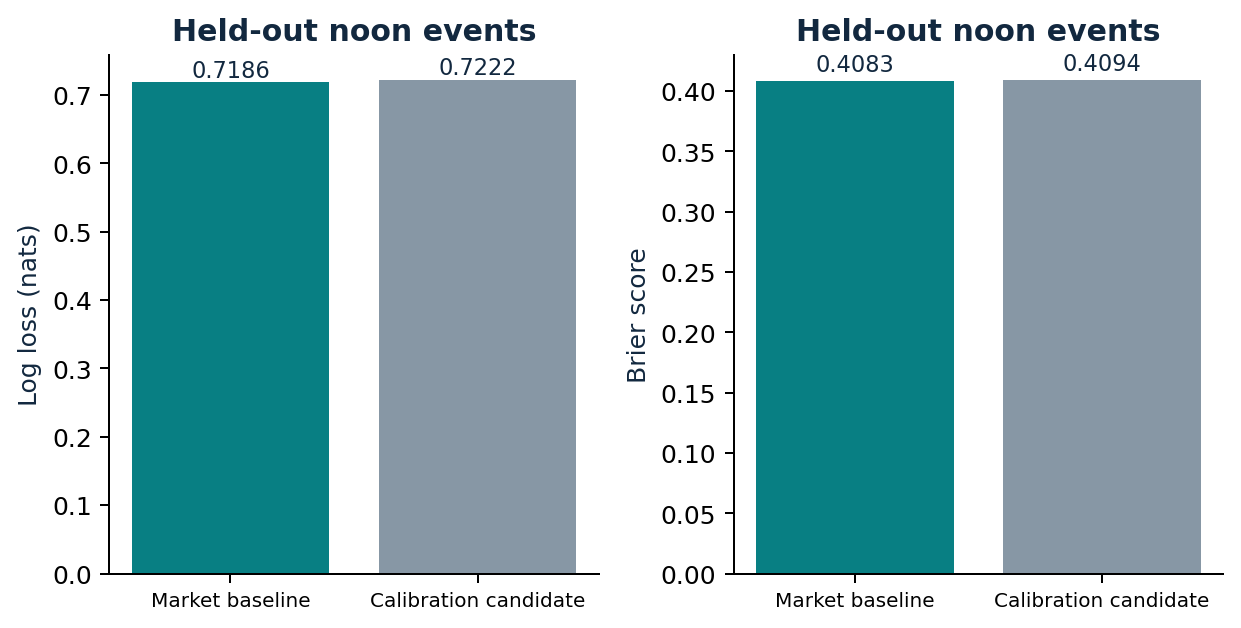

Figure 4. Held-out scores for the market-derived baseline and the rejected calibration candidate. Lower is better; validation selected the baseline.

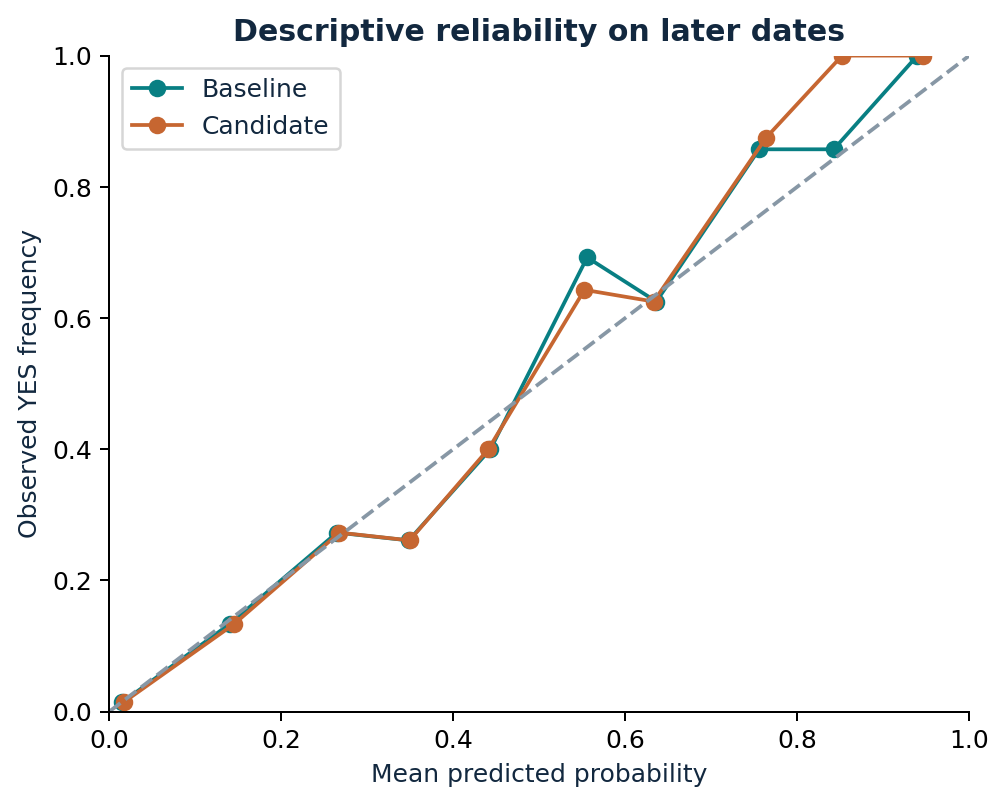

Figure 5. Pooled reliability bins on held-out events. Contracts within an event are dependent; this curve is descriptive, not an independent-bin significance test.

The Brier convention sums squared errors across outcomes within each event.


In [4]:
show_figure(4)
show_figure(5)
print('The Brier convention sums squared errors across outcomes within each event.')